# 02 · Data cleaning: nine steps from raw records to one hourly master table

<a href="https://colab.research.google.com/github/FarhanRajputFelix/saans/blob/main/notebooks/02_data_cleaning.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Input:** the raw tables from notebook 01. **Output:** `data/processed/master_hourly.parquet` (one row per city per hour), `data/processed/fires_clean.parquet`, and the Data Quality Report in `reports/data_quality_report.md`.

Cleaning is the core of SAANS. Every step follows the same pattern: **why** it is needed, the **rule**, and the **before and after counts**. Every action goes through one `log()` function, and that log becomes the Data Quality Report at the end of the notebook.

| Step | What it fixes |
|---|---|
| 1 | Time alignment: one clock (UTC) for every source |
| 2 | Units: everything in ug/m3, AQI computed by us |
| 3 | Duplicates and physically invalid values |
| 4 | Sensor faults: stuck sensors and readings at the sensor's limit |
| 5 | Glitch or real event: one-sensor spikes vs city-wide smog |
| 6 | Humidity correction for low-cost sensors |
| 7 | Fire data: confidence, static heat sources, double-counted satellite passes |
| 8 | Missing values: short gaps filled, long gaps flagged, test seasons never touched |
| 9 | Integration: one hourly master table per city |

**Setup.** Runs the same way locally and in Google Colab. In Colab it clones the repo (which includes the cleaned data) and reads API keys from Colab's *Secrets* panel (key icon on the left).

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules:
    if not os.path.exists("/content/saans"):
        subprocess.run(["git", "clone", "-q", "https://github.com/FarhanRajputFelix/saans.git", "/content/saans"], check=True)
    os.chdir("/content/saans")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm", "shap", "python-dotenv"], check=True)
    from google.colab import userdata
    for k in ["OPENAQ_API_KEY", "FIRMS_MAP_KEY", "GEMINI_API_KEY", "GROQ_API_KEY"]:
        try:
            os.environ[k] = userdata.get(k)
        except Exception:
            pass
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # work from the repo root so `saans` and `data/` resolve
sys.path.insert(0, os.getcwd())

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

from saans.config import CITIES, INTERIM, PROCESSED, REPORTS, LOCAL_TZ
from saans.aqi import BREAKPOINTS, pm25_to_aqi
from saans import viz

viz.use_style()
pd.set_option("display.width", 160)
FIG = REPORTS / "figures"
for d in (PROCESSED, FIG):
    d.mkdir(parents=True, exist_ok=True)

# Held-out test seasons (Oct-Jan). Nothing in them is ever interpolated or used to fit anything.
TEST_SEASONS = [("2024-10-01", "2025-02-01"), ("2025-10-01", "2026-02-01")]
def in_test(t: pd.Series) -> pd.Series:
    t = t.dt.tz_convert(None)
    return np.logical_or.reduce([(t >= a) & (t < b) for a, b in TEST_SEASONS])

LOG = []
def log(step, source, action, before, after, note=""):
    """Record one cleaning action. The Data Quality Report is built from these rows."""
    LOG.append({"step": step, "source": source, "action": action, "rows_before": before,
                "rows_after": after, "removed": before - after, "note": note})
    print(f"[step {step}] {source}: {action}: {before:,} -> {after:,} ({before - after:,} removed). {note}")

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

### Load the raw tables

In [3]:
wx = pd.read_parquet(INTERIM / "weather_hourly.parquet")
aq = pd.read_parquet(INTERIM / "openaq_hourly.parquet")
sensors = pd.read_csv(INTERIM / "openaq_sensors.csv")
fires = pd.read_parquet(INTERIM / "firms_fires.parquet")
news = pd.read_csv(INTERIM / "news_headlines.csv", parse_dates=["time_utc"])

meta = sensors.drop_duplicates("sensor_id").set_index("sensor_id")[["provider", "location", "lat", "lon", "units"]]
aq = aq.join(meta, on="sensor_id")
aq["kind"] = np.where(aq.is_monitor, "reference", "low-cost")
pm10_raw = pd.read_parquet(INTERIM / "openaq_pm10_hourly.parquet")
RAW = {"weather": len(wx), "openaq": len(aq), "openaq_pm10": len(pm10_raw), "fires": len(fires), "news": len(news)}
raw_per_sensor = aq.groupby(["sensor_id", "provider", "city"]).size().rename("hours_received")
pd.Series(RAW, name="raw records").to_frame().style.format("{:,}")

,raw records
weather,"266,760"
openaq,"587,969"
openaq_pm10,"5,904"
fires,"1,185,836"
news,"2,255"


## Step 1 · Time alignment

**Why.** Each source keeps time differently. OpenAQ labels each hourly average by the UTC hour it starts. NASA FIRMS stores time as an `HHMM` integer in UTC (`845` = 08:45), parsed into a timestamp during ingestion. Open-Meteo returns whatever zone you ask for, and we asked for UTC. If one table were in Pakistan time and another in UTC, every join would silently shift by 5 hours.

**Rule.** Store everything in UTC, snapped to the hour. Add a Pakistan-time column only where people need the local clock (hour of day, event dates, the dashboard).

In [4]:
off_hour = int((aq.time_utc != aq.time_utc.dt.floor("h")).sum())
aq["time_utc"] = aq.time_utc.dt.floor("h")
fires["hour_utc"] = fires.time_utc.dt.floor("h")
for df in (wx, aq):
    df["time_pkt"] = df.time_utc.dt.tz_convert(LOCAL_TZ)
print("Example FIRMS conversions (acq_time HHMM -> UTC timestamp):")
print(fires[["acq_date", "acq_time", "time_utc"]].drop_duplicates("acq_time").head(3).to_string(index=False))
log(1, "OpenAQ", "timestamps checked and snapped to the UTC hour", len(aq), len(aq), f"{off_hour} off-hour stamps snapped")
log(1, "FIRMS", "HHMM integer times parsed to UTC; hour bucket added", len(fires), len(fires))

Example FIRMS conversions (acq_time HHMM -> UTC timestamp):
  acq_date  acq_time                  time_utc
2020-01-01       534 2020-01-01 05:34:00+00:00
2020-01-01       537 2020-01-01 05:37:00+00:00
2020-01-01       838 2020-01-01 08:38:00+00:00
[step 1] OpenAQ: timestamps checked and snapped to the UTC hour: 587,969 -> 587,969 (0 removed). 0 off-hour stamps snapped
[step 1] FIRMS: HHMM integer times parsed to UTC; hour bucket added: 1,185,836 -> 1,185,836 (0 removed). 


## Step 2 · Unit standardization and our own AQI

**Why.** Public AQI figures for Pakistan mix scales: Pakistan EPA, US EPA (old and new breakpoints), and commercial sites that extend beyond 500 (the "AQI 1,165" headline of November 2024). Comparing those numbers is meaningless.

**Rule.** Keep raw concentrations in ug/m3 and compute the US EPA AQI ourselves from the 24-hour mean, with the breakpoints EPA revised in February 2024 (`saans/aqi.py`). A "hazardous day" is AQI above 300, which means a 24-hour mean of 225.5 ug/m3 or more.

In [5]:
print("Units reported by PM2.5 sensors:", sensors[sensors.parameter == "pm25"].units.value_counts().to_dict())
pd.DataFrame(BREAKPOINTS, columns=["PM2.5 from", "PM2.5 to", "AQI from", "AQI to", "category"])

Units reported by PM2.5 sensors: {'µg/m³': 243}


,PM2.5 from,PM2.5 to,AQI from,AQI to,category
0,0.0,9.0,0,50,Good
1,9.1,35.4,51,100,Moderate
2,35.5,55.4,101,150,Unhealthy for Sensitive Groups
3,55.5,125.4,151,200,Unhealthy
4,125.5,225.4,201,300,Very Unhealthy
5,225.5,325.4,301,500,Hazardous


In [6]:
log(2, "OpenAQ", "units verified (all ug/m3); AQI to be computed from 24 h means", len(aq), len(aq))

[step 2] OpenAQ: units verified (all ug/m3); AQI to be computed from 24 h means: 587,969 -> 587,969 (0 removed). 


## Step 3 · Duplicates and invalid values

**Why.** APIs repeat records across pages, sensors report negative numbers when they drift below zero, and a broken sensor can report concentrations no city has ever seen. An hourly average built from only a few minutes of data is also unreliable.

**Rules.**
* one value per sensor per hour (duplicates dropped);
* no empty readings (reference monitors publish missing hours as nulls), no negative concentrations, and no readings below **1 ug/m3**: that is below the instruments' detection floor, and a city's hourly PM2.5 is never truly zero, while a faulting sensor reports exactly 0;
* no hourly value above **1,000 ug/m3**, the measuring limit of the low-cost sensors in this network;
* an hour must contain at least **75% of the sensor's normal number of readings**. OpenAQ also publishes a `percentComplete` field, but it assumes 12 readings an hour for every sensor. The Clarity monitor in Lahore reports every 15 to 20 minutes (3 to 4 readings an hour), so OpenAQ marks all its good hours as "25% complete". Using that field would silently delete Lahore's only reference-quality record after March 2025. Each sensor is therefore judged against its own typical (median) count.

In [7]:
print("Largest raw hourly values by kind:")
print(aq.groupby("kind").value.describe(percentiles=[.5, .99, .999]).round(1))

Largest raw hourly values by kind:


              count   mean    std  min   50%    99%  99.9%    max
kind                                                             
low-cost   437957.0  123.6  109.2  0.0  81.8  458.0  591.0  987.0
reference  124457.0   70.6   81.4  0.0  42.0  419.0  670.0  985.0


In [8]:
print("Null readings by provider:", aq[aq.value.isna()].groupby("provider").size().to_dict())
print("Median readings per hour by provider:", aq.groupby("provider").observed_count.median().to_dict())
print("OpenAQ's own percentComplete, median by provider:", aq.groupby("provider").percent_complete.median().to_dict())

Null readings by provider: {'AirNow': 10186, 'StateAir Islamabad': 6586, 'StateAir Lahore': 8783}
Median readings per hour by provider: {'AirGradient': 1.0, 'AirNow': 1.0, 'Clarity': 3.0, 'Hawanama': 1.0, 'StateAir Islamabad': 1.0, 'StateAir Lahore': 1.0}


OpenAQ's own percentComplete, median by provider: {'AirGradient': 100.0, 'AirNow': 100.0, 'Clarity': 25.0, 'Hawanama': 100.0, 'StateAir Islamabad': 100.0, 'StateAir Lahore': 100.0}


In [9]:
n = len(aq); aq = aq.drop_duplicates(["sensor_id", "time_utc"]); log(3, "OpenAQ", "duplicate sensor-hours dropped", n, len(aq))
n = len(aq); aq = aq[aq.value.notna()]; log(3, "OpenAQ", "empty (null) readings dropped", n, len(aq), "reference monitors' missing-hour markers")
n = len(aq); aq = aq[aq.value >= 0]; log(3, "OpenAQ", "negative concentrations dropped", n, len(aq))
n = len(aq); aq = aq[aq.value >= 1]
log(3, "OpenAQ", "zero readings dropped (below 1 ug/m3)", n, len(aq),
    "below the instruments' detection floor; urban hourly PM2.5 is never truly zero, a faulting sensor reports 0")
n = len(aq); aq = aq[aq.value <= 1000]; log(3, "OpenAQ", "values above 1,000 ug/m3 dropped", n, len(aq))
typical = aq.groupby("sensor_id").observed_count.transform("median")
n = len(aq); aq = aq[aq.observed_count.isna() | (aq.observed_count >= 0.75 * typical)]
log(3, "OpenAQ", "hours with <75% of the sensor's normal readings dropped", n, len(aq),
    "judged per sensor; OpenAQ's percentComplete assumes 12 readings/hour for all sensors")

n = len(fires); fires = fires.drop_duplicates(["latitude", "longitude", "time_utc", "source"])
log(3, "FIRMS", "exact duplicate detections dropped", n, len(fires))

checks = {"relative_humidity_2m": (0, 100), "wind_speed_10m": (0, 60), "temperature_2m": (-30, 55),
          "boundary_layer_height": (0, 6000), "precipitation": (0, 300)}
bad = sum(int((~wx[c].between(lo, hi) & wx[c].notna()).sum()) for c, (lo, hi) in checks.items())
log(3, "Weather", "physical range checks (humidity, wind, temperature, BLH, rain)", len(wx), len(wx), f"{bad} values out of range")
log(3, "News", "duplicate links and near-identical headlines dropped at download", len(news), len(news),
    "de-duplicated in saans/ingest/news.py")

[step 3] OpenAQ: duplicate sensor-hours dropped: 587,969 -> 587,969 (0 removed). 


[step 3] OpenAQ: empty (null) readings dropped: 587,969 -> 562,414 (25,555 removed). reference monitors' missing-hour markers
[step 3] OpenAQ: negative concentrations dropped: 562,414 -> 562,414 (0 removed). 


[step 3] OpenAQ: zero readings dropped (below 1 ug/m3): 562,414 -> 561,394 (1,020 removed). below the instruments' detection floor; urban hourly PM2.5 is never truly zero, a faulting sensor reports 0
[step 3] OpenAQ: values above 1,000 ug/m3 dropped: 561,394 -> 561,394 (0 removed). 


[step 3] OpenAQ: hours with <75% of the sensor's normal readings dropped: 561,394 -> 559,860 (1,534 removed). judged per sensor; OpenAQ's percentComplete assumes 12 readings/hour for all sensors


[step 3] FIRMS: exact duplicate detections dropped: 1,185,836 -> 1,185,836 (0 removed). 


[step 3] Weather: physical range checks (humidity, wind, temperature, BLH, rain): 266,760 -> 266,760 (0 removed). 0 values out of range
[step 3] News: duplicate links and near-identical headlines dropped at download: 2,255 -> 2,255 (0 removed). de-duplicated in saans/ingest/news.py


## Step 4 · Sensor faults

**Why.** A sensor that freezes keeps sending its last value. Real air never holds exactly the same concentration for six hours, so a long flat run is a fault, not a calm day. A sensor that hits its maximum keeps reporting that ceiling while the real value is higher.

**Rules.**
* **Stuck:** the same value for 6 or more consecutive hours. The whole run is removed.
* **At the limit:** a sensor's maximum value repeated 3 or more times (at 500 ug/m3 or above) is treated as saturation.

In [10]:
aq = aq.sort_values(["sensor_id", "time_utc"]).reset_index(drop=True)
prev_val = aq.groupby("sensor_id").value.shift()
prev_t = aq.groupby("sensor_id").time_utc.shift()
same = (aq.value == prev_val) & (aq.time_utc - prev_t == pd.Timedelta("1h"))
run_id = (~same).cumsum()
aq["run_len"] = aq.groupby(run_id).value.transform("size")
stuck = aq.run_len >= 6
print("Stuck-run hours by kind:", aq[stuck].groupby("kind").size().to_dict())
example = aq[stuck].groupby(run_id[stuck]).agg(sensor=("location", "first"), start=("time_pkt", "first"),
                                               hours=("value", "size"), value=("value", "first"))
print(example.sort_values("hours", ascending=False).head(5).to_string(index=False))
n = len(aq); aq = aq[~stuck]; log(4, "OpenAQ", "stuck sensor runs (same value 6+ hours) removed", n, len(aq))

smax = aq.groupby("sensor_id").value.transform("max")
nmax = aq.groupby("sensor_id").value.transform(lambda v: (v == v.max()).sum())
sat = (aq.value == smax) & (nmax >= 3) & (smax >= 500)
n = len(aq); aq = aq[~sat]; log(4, "OpenAQ", "readings stuck at the sensor's maximum removed", n, len(aq))

Stuck-run hours by kind: {'low-cost': 30, 'reference': 186}
                    sensor                     start  hours  value
US Diplomatic Post: Lahore 2024-06-01 05:00:00+05:00    105   67.0
US Diplomatic Post: Lahore 2024-05-29 21:00:00+05:00     30   67.0
US Diplomatic Post: Lahore 2024-05-31 14:00:00+05:00     14   67.0
                   Karachi 2022-01-19 06:00:00+05:00     12  257.0
US Diplomatic Post: Lahore 2024-05-31 06:00:00+05:00      7   67.0


[step 4] OpenAQ: stuck sensor runs (same value 6+ hours) removed: 559,860 -> 559,644 (216 removed). 


[step 4] OpenAQ: readings stuck at the sensor's maximum removed: 559,644 -> 559,644 (0 removed). 


## Step 5 · Glitch or real event?

**Why.** A sudden jump can be a fault (an insect in the inlet, a power surge) or real pollution (fireworks, a crop-burning surge). Deleting every spike would delete the very events SAANS must forecast; keeping every spike would teach the model noise.

**Rules.**
* **Neighbour test** (wherever a sensor has 2 or more neighbours within 5 km reporting that hour): a reading more than 3x the neighbours' median *and* more than 100 ug/m3 above it is a glitch. Smog that all neighbours also see is kept.
* **Isolated-spike test** (for single-monitor periods, e.g. the US posts in 2020-2023): a reading more than 3x *both* the hour before and the hour after, and 150+ ug/m3 above them, is a glitch, except on known fireworks nights (New Year's Eve and Shab-e-Barat, approximate dates), where short spikes are real.
* **Dropout test** (the mirror image): a reading below a quarter of *both* neighbouring hours while the air around it is polluted (60+ ug/m3), or below a quarter of the neighbours' median, is a glitch. Air cannot clean itself in one hour and dirty itself again the next. This rule was added after the dashboard showed Lahore falling to **0 ug/m3** for one hour on 3 Nov 2024, in the middle of record smog: the Clarity monitor reported 0.0 between readings of 374 and 334 while the reference monitor was offline.
* Genuine extremes are **kept and tagged** (`extreme_event` in the master table: city PM2.5 of 250+ ug/m3; `fireworks_night` for the protected nights).

In [11]:
def neighbour_stats(city_df: pd.DataFrame) -> pd.DataFrame:
    wide = city_df.pivot_table(index="time_utc", columns="sensor_id", values="value")
    ids = list(wide.columns)
    lat, lon = meta.loc[ids, "lat"].to_numpy(), meta.loc[ids, "lon"].to_numpy()
    dist = haversine_km(lat[:, None], lon[:, None], lat[None, :], lon[None, :])
    out = []
    for k, sid in enumerate(ids):
        nb = [ids[j] for j in range(len(ids)) if j != k and dist[k, j] <= 5]
        if not nb:
            continue
        out.append(pd.DataFrame({"sensor_id": sid, "time_utc": wide.index,
                                 "nb_median": wide[nb].median(axis=1).to_numpy(),
                                 "nb_count": wide[nb].notna().sum(axis=1).to_numpy()}))
    return pd.concat(out) if out else pd.DataFrame(columns=["sensor_id", "time_utc", "nb_median", "nb_count"])

nb = pd.concat([neighbour_stats(g) for _, g in aq.groupby("city")], ignore_index=True)
aq = aq.merge(nb, on=["sensor_id", "time_utc"], how="left")
has_nb = aq.nb_count.fillna(0) >= 2
glitch_nb = has_nb & (aq.value > 3 * aq.nb_median) & (aq.value - aq.nb_median > 100)

# fireworks nights in Pakistan time: New Year's Eve, and Shab-e-Barat (15 Sha'ban; approximate dates)
fireworks = ["2020-04-08", "2021-03-28", "2022-03-18", "2023-03-07", "2024-02-25", "2025-02-14"]
fireworks += [f"{y}-12-31" for y in range(2019, 2026)]
night = aq.time_pkt.dt.tz_localize(None)
protected = np.zeros(len(aq), bool)
for d in pd.to_datetime(fireworks):
    protected |= ((night >= d + pd.Timedelta(hours=18)) & (night < d + pd.Timedelta(hours=33))).to_numpy()

g = aq.groupby("sensor_id")
prev_v, next_v = g.value.shift(1), g.value.shift(-1)
contiguous = ((aq.time_utc - g.time_utc.shift(1)) == pd.Timedelta("1h")) & ((g.time_utc.shift(-1) - aq.time_utc) == pd.Timedelta("1h"))
glitch_t = (~has_nb & contiguous & ~protected & (aq.value > 3 * prev_v) & (aq.value > 3 * next_v)
            & (aq.value - np.maximum(prev_v, next_v) > 150))
drop_t = (~has_nb & contiguous & (aq.value < 0.25 * prev_v) & (aq.value < 0.25 * next_v) & (np.minimum(prev_v, next_v) > 60))
drop_nb = has_nb & (aq.value < 0.25 * aq.nb_median) & (aq.nb_median - aq.value > 100)
print(f"spikes: {int(glitch_nb.sum())} by neighbours, {int(glitch_t.sum())} isolated | "
      f"dropouts: {int(drop_nb.sum())} by neighbours, {int(drop_t.sum())} isolated | "
      f"spikes protected on fireworks nights: {int((protected & (aq.value > 3 * prev_v)).sum())}")
print("Example dropout removed:")
print(aq.loc[drop_t | drop_nb, ["location", "time_pkt", "value"]].assign(prev=prev_v, next=next_v).head(4).to_string(index=False))
n = len(aq); aq = aq[~(glitch_nb | glitch_t)]
log(5, "OpenAQ", "single-sensor spikes removed (neighbour and isolated tests)", n, len(aq),
    f"{int(glitch_nb.sum())} neighbour, {int(glitch_t.sum())} isolated")
bad = (drop_t | drop_nb).reindex(aq.index)
n = len(aq); aq = aq[~bad]
log(5, "OpenAQ", "single-sensor dropouts removed (sudden falls to near zero)", n, len(aq),
    "added after the dashboard showed Lahore at 0 ug/m3 on 3 Nov 2024")

spikes: 1539 by neighbours, 25 isolated | dropouts: 1110 by neighbours, 4 isolated | spikes protected on fireworks nights: 3
Example dropout removed:
                  location                  time_pkt  value  prev  next
US Diplomatic Post: Lahore 2021-03-06 21:00:00+05:00   14.0 119.0  73.0
US Diplomatic Post: Lahore 2023-07-23 11:00:00+05:00   10.0  91.0  74.0
US Diplomatic Post: Lahore 2023-07-25 21:00:00+05:00   15.0  80.0  90.0
US Diplomatic Post: Lahore 2023-10-12 10:00:00+05:00   52.0 220.0 411.0


[step 5] OpenAQ: single-sensor spikes removed (neighbour and isolated tests): 559,644 -> 558,080 (1,564 removed). 1539 neighbour, 25 isolated


[step 5] OpenAQ: single-sensor dropouts removed (sudden falls to near zero): 558,080 -> 556,966 (1,114 removed). added after the dashboard showed Lahore at 0 ug/m3 on 3 Nov 2024


## Step 6 · Humidity correction for low-cost sensors

**Why.** Low-cost sensors (AirGradient and similar, built on Plantower laser counters) count particles optically. In humid air particles absorb water and swell, so these sensors over-read PM2.5, by a lot in Punjab's damp winter nights. Reference monitors dry the air first and are not affected.

**Rule.** The US EPA's published nationwide correction for Plantower-based sensors (Barkjohn et al., 2021), using ERA5 relative humidity at the city:

$$PM_{2.5,\,corrected} = 0.524 \times PM_{2.5,\,raw} - 0.0862 \times RH + 5.75$$

**Check before applying.** Some providers (e.g. Clarity) may already calibrate their data, and correcting twice would make it worse. So for every low-cost provider we compare raw and corrected values with a reference monitor in the same city and hour, using **only hours outside the test seasons**. The correction is applied **only to a provider for which this check shows it helps**; a provider with no check stays raw.

*Why the rule is worded this way.* An earlier version applied the correction to every provider unless the check showed it hurt, so Hawanama, which has no reference overlap before the test seasons, was corrected by default. That roughly halved its readings, and when 56 Hawanama sensors joined Lahore on 19 Nov 2025 they outnumbered the other networks and pulled the city median down: Lahore's cleaned PM2.5 fell from about 250 to 149 ug/m3 overnight, a drop no weather explains. A later diagnosis against Islamabad's reference monitor (reference 112, Hawanama raw 90, corrected 47) confirmed the correction made Hawanama worse. That diagnosis uses test-season hours, so it is reported here but did not set the rule; the rule follows from the principle alone.

In [12]:
aq = aq.merge(wx[["city", "time_utc", "relative_humidity_2m"]], on=["city", "time_utc"], how="left")
aq["value_raw"] = aq.value
aq["value_epa"] = (0.524 * aq.value_raw - 0.0862 * aq.relative_humidity_2m + 5.75).clip(lower=0)

ref = aq[aq.kind == "reference"].groupby(["city", "time_utc"]).value_raw.mean().rename("reference")
lc = (aq[(aq.kind == "low-cost") & ~in_test(aq.time_utc)]
      .groupby(["provider", "city", "time_utc"]).agg(raw=("value_raw", "median"), epa=("value_epa", "median"))
      .join(ref).dropna(subset=["reference"]).reset_index())
correction_check = (lc.groupby("provider")
                    .apply(lambda g: pd.Series({
                        "overlap_hours": len(g), "cities": ", ".join(sorted(g.city.unique())),
                        "reference_mean": round(g.reference.mean(), 1),
                        "raw_mean": round(g.raw.mean(), 1), "corrected_mean": round(g.epa.mean(), 1),
                        "raw_MAE": round((g.raw - g.reference).abs().mean(), 1),
                        "corrected_MAE": round((g.epa - g.reference).abs().mean(), 1)}), include_groups=False)
                    .reset_index())
correction_check

,provider,overlap_hours,cities,reference_mean,raw_mean,corrected_mean,raw_MAE,corrected_MAE
0,AirGradient,2772,islamabad,34.0,36.0,18.6,9.8,15.6
1,Clarity,6331,"karachi, lahore",122.4,83.6,43.8,43.4,78.7


In [13]:
helps = set(correction_check.loc[(correction_check.overlap_hours >= 200)
                                 & (correction_check.corrected_MAE < correction_check.raw_MAE), "provider"])
apply = (aq.kind == "low-cost") & aq.provider.isin(helps)
aq["value"] = np.where(apply, aq.value_epa, aq.value_raw)
aq["humidity_corrected"] = apply
unchecked = sorted(set(aq.loc[aq.kind == "low-cost", "provider"]) - set(correction_check.provider))
print("Correction applied to:", sorted(helps) or "no provider",
      "| left raw because the check showed it hurts:", sorted(set(correction_check.provider) - helps),
      "| left raw because no pre-test check exists:", unchecked)
(PROCESSED / "humidity_correction.json").write_text(json.dumps({"corrected_providers": sorted(helps),
                                                                "rule": "corrected only where the pre-test check shows it helps"}))
log(6, "OpenAQ", "EPA humidity correction applied only where a pre-test check shows it helps", len(aq), len(aq),
    f"{int(apply.sum()):,} sensor-hours corrected; raw: {', '.join(sorted(set(correction_check.provider) - helps) + unchecked)}")

Correction applied to: no provider | left raw because the check showed it hurts: ['AirGradient', 'Clarity'] | left raw because no pre-test check exists: ['Hawanama']
[step 6] OpenAQ: EPA humidity correction applied only where a pre-test check shows it helps: 556,966 -> 556,966 (0 removed). 0 sensor-hours corrected; raw: AirGradient, Clarity, Hawanama


## Step 7 · Fire data cleaning

**Why.** Not every FIRMS detection is a crop fire. Low-confidence pixels are often sun glint or hot ground; steel mills, brick kilns and gas flares glow year-round and would make the fire index permanently high; and the same field fire can be seen by several satellite passes on one day, which would count it two or three times.

**Rules.**
* drop **low-confidence** detections (VIIRS class `l`; MODIS confidence below 30);
* keep only NASA's `type = 0` (presumed vegetation fire): this removes **static land sources** (type 2, industrial heat) and offshore detections (type 3);
* **one fire per ~1 km cell per day and per day/night pass**: detections from the satellite passes minutes or a few hours apart are merged, keeping the strongest fire radiative power (FRP).

In [14]:
conf = fires.confidence.astype(str)
is_low = np.where(fires.source.str.startswith("VIIRS"), conf == "l", pd.to_numeric(conf, errors="coerce") < 30)
n = len(fires); fires = fires[~is_low]; log(7, "FIRMS", "low-confidence detections dropped", n, len(fires))
print("Detection types:", fires.type.value_counts().to_dict(), "(0 = vegetation fire, 2 = static land source, 3 = offshore)")
# NASA's near-real-time feed (used by the live forecast) carries no `type`, so save where the static sources are
static = fires[fires.type != 0]
static_cells = sorted(set((static.latitude * 100).round().astype(int).astype(str) + "_" + (static.longitude * 100).round().astype(int).astype(str)))
(PROCESSED / "static_fire_cells.json").write_text(json.dumps(static_cells))
print(f"{len(static_cells):,} ~1 km cells hold static heat sources (saved for the live forecast)")
n = len(fires); fires = fires[fires.type == 0]; log(7, "FIRMS", "static industrial sources and offshore detections dropped (type != 0)", n, len(fires))

fires["cell"] = (fires.latitude * 100).round().astype(int).astype(str) + "_" + (fires.longitude * 100).round().astype(int).astype(str)
n = len(fires)
fires = (fires.sort_values("frp", ascending=False)
         .groupby(["cell", "acq_date", "daynight"], as_index=False)
         .agg(latitude=("latitude", "first"), longitude=("longitude", "first"), frp=("frp", "first"),
              time_utc=("time_utc", "min"), passes=("source", "size"), n_instruments=("source", "nunique")))
fires["hour_utc"] = fires.time_utc.dt.floor("h")
log(7, "FIRMS", "repeat detections of the same fire merged (one per 1 km cell, day and pass)", n, len(fires),
    f"{int((fires.passes > 1).sum()):,} fires were seen by more than one pass")

[step 7] FIRMS: low-confidence detections dropped: 1,185,836 -> 1,036,047 (149,789 removed). 
Detection types: {0: 999736, 2: 36129, 3: 182} (0 = vegetation fire, 2 = static land source, 3 = offshore)


2,331 ~1 km cells hold static heat sources (saved for the live forecast)


[step 7] FIRMS: static industrial sources and offshore detections dropped (type != 0): 1,036,047 -> 999,736 (36,311 removed). 


[step 7] FIRMS: repeat detections of the same fire merged (one per 1 km cell, day and pass): 999,736 -> 815,434 (184,302 removed). 139,394 fires were seen by more than one pass


## Step 8 · Missing values

Two different gaps to handle.

**(a) PM2.5.** First each city gets one hourly series: the reference monitor where one reports that hour (mean if two feeds report), otherwise the median of the corrected low-cost sensors. Then:
* gaps of **up to 3 hours** are filled by linear interpolation and flagged (`pm25_interpolated`), **outside the test seasons only**;
* longer gaps stay empty (no target value for those hours);
* the 2024 and 2025 test seasons are **never** filled: the models must be scored on real measurements only.

In [15]:
# Islamabad's two reference feeds (StateAir and AirNow) are the same US Embassy monitor: check, then average
isl = aq[(aq.city == "islamabad") & (aq.kind == "reference")].pivot_table(index="time_utc", columns="provider", values="value").dropna()
if isl.shape[1] == 2:
    print(f"Islamabad reference feeds: {len(isl):,} overlapping hours, {(isl.iloc[:, 0] == isl.iloc[:, 1]).mean():.0%} identical, "
          f"r = {isl.corr().iloc[0, 1]:.3f}: one monitor published twice, so the two are averaged")
ref_h = aq[aq.kind == "reference"].groupby(["city", "time_utc"]).value.mean().rename("pm25_ref")
low_h = aq[aq.kind == "low-cost"].groupby(["city", "time_utc"]).agg(pm25_low=("value", "median"), n_low=("value", "size"))
pm = pd.concat([ref_h, low_h], axis=1).reset_index()
pm["pm25"] = pm.pm25_ref.fillna(pm.pm25_low)
pm["pm25_source"] = np.where(pm.pm25_ref.notna(), "reference", "low-cost")
print(pm.groupby(["city", "pm25_source"]).size().unstack(fill_value=0))

Islamabad reference feeds: 15,913 overlapping hours, 87% identical, r = 0.978: one monitor published twice, so the two are averaged


pm25_source  low-cost  reference
city                            
faisalabad       5282          0
islamabad         674      44346
karachi          5711      31568
lahore           9304      32321
multan           5457          0


In [16]:
grid = wx[["city", "time_utc"]]
pm = grid.merge(pm, on=["city", "time_utc"], how="left").sort_values(["city", "time_utc"]).reset_index(drop=True)

# second dropout pass on the combined city series: when the reference monitor is offline for one hour, the
# fallback low-cost value can be a dropout the sensor-level rule could not see (e.g. Lahore 3 Nov 2024, 10:00)
gp = pm.groupby("city").pm25
prev_c, next_c = gp.shift(1), gp.shift(-1)
city_drop = (pm.pm25 < 0.25 * prev_c) & (pm.pm25 < 0.25 * next_c) & (np.minimum(prev_c, next_c) > 60)
print("City-level dropouts removed:", pm.loc[city_drop, ["city", "time_utc", "pm25"]].assign(prev=prev_c, next=next_c).head(6).to_string(index=False))
n = int(pm.pm25.notna().sum())
pm.loc[city_drop, ["pm25", "pm25_source"]] = np.nan
log(5, "PM2.5 city series", "city-level dropouts removed (second pass after combining sensors)", n, int(pm.pm25.notna().sum()))
before = int(pm.pm25.notna().sum())
filled = pm.groupby("city").pm25.transform(lambda s: s.interpolate(limit=3, limit_area="inside"))
gap_ok = filled.notna() & pm.pm25.isna()
# only fill gaps whose total length is <= 3 h (interpolate(limit=3) would also fill the start of longer gaps)
isna = pm.pm25.isna()
gap_id = (isna != isna.groupby(pm.city).shift()).cumsum()
gap_len = isna.groupby(gap_id).transform("sum")
fill_mask = gap_ok & (gap_len <= 3) & ~in_test(pm.time_utc)
pm["pm25_interpolated"] = fill_mask
pm.loc[fill_mask, "pm25"] = filled[fill_mask]
pm.loc[fill_mask, "pm25_source"] = "interpolated"
log(8, "PM2.5 city series", "short gaps (<=3 h) interpolated outside the test seasons", before, before,
    f"{int(fill_mask.sum()):,} city-hours filled; test seasons untouched")
coverage = pm.groupby("city").pm25.apply(lambda s: f"{s.notna().mean():.0%}")
print("Share of hours with a PM2.5 value:", coverage.to_dict())

# Diagnosis only (nothing is fitted on it): the city series must not jump when a new sensor network
# switches on. Hawanama joined Lahore on 19 Nov 2025; with the corrected rule in step 6 there is no step.
lah = pm[pm.city == "lahore"].assign(day=lambda d: d.time_utc.dt.tz_convert(LOCAL_TZ).dt.date.astype(str))
lah = lah[lah.day.between("2025-11-14", "2025-11-24")].groupby("day").agg(pm25=("pm25", "mean"), low_cost_sensors=("n_low", "median"))
print("Lahore daily mean around the day Hawanama joined:")
print(lah.round(0).T.to_string())

# flag every remaining gap with its length, so a reader can tell a missing hour from a missing month
isna = pm.pm25.isna()
gap_id = (isna != isna.groupby(pm.city).shift()).cumsum()
pm["gap_hours"] = np.where(isna, isna.groupby(gap_id).transform("sum"), 0).astype(int)
pm["long_gap"] = pm.gap_hours > 3
log(8, "PM2.5 city series", "remaining gaps flagged with their length (long_gap = more than 3 h)", len(pm), len(pm),
    f"{int(pm.long_gap.sum()):,} city-hours sit inside long gaps (no target, never filled)")

City-level dropouts removed:    city                  time_utc  pm25  prev  next
karachi 2024-01-02 14:00:00+00:00  4.01  83.0  89.0
karachi 2024-01-03 06:00:00+00:00  3.47 133.0  99.0
karachi 2024-01-08 15:00:00+00:00  6.62  84.0 128.0
 lahore 2023-12-24 02:00:00+00:00 48.50 714.0 208.0
[step 5] PM2.5 city series: city-level dropouts removed (second pass after combining sensors): 134,663 -> 134,659 (4 removed). 


[step 8] PM2.5 city series: short gaps (<=3 h) interpolated outside the test seasons: 134,659 -> 134,659 (0 removed). 2,937 city-hours filled; test seasons untouched
Share of hours with a PM2.5 value: {'faisalabad': '10%', 'islamabad': '85%', 'karachi': '72%', 'lahore': '80%', 'multan': '10%'}


Lahore daily mean around the day Hawanama joined:
day               2025-11-14  2025-11-15  2025-11-16  2025-11-17  2025-11-18  2025-11-19  2025-11-20  2025-11-21  2025-11-22  2025-11-23  2025-11-24
pm25                   277.0       263.0       220.0       244.0       278.0       249.0       239.0       242.0       236.0       202.0       184.0
low_cost_sensors        19.0        20.0        19.0        21.0        20.0        55.0        42.0        44.0        52.0        48.0        43.0
[step 8] PM2.5 city series: remaining gaps flagged with their length (long_gap = more than 3 h): 266,760 -> 266,760 (0 removed). 129,011 city-hours sit inside long gaps (no target, never filled)


**(b) Boundary layer height (finding W1).** BLH is missing for 1 Jan to 30 Jun 2024 in every city. It is the most physically important weather variable for smog, so instead of dropping six months we **impute** it from the 12 weather variables that are complete, plus hour of day and month, with a LightGBM model trained on all other hours.

The imputation is tested honestly first: hide **Jan to Jun 2023** (whose true values we know), train on the rest, and measure the error on the hidden half-year.

Validation on hidden Jan-Jun 2023: MAE = 148 m, correlation = 0.911, true median = 210 m


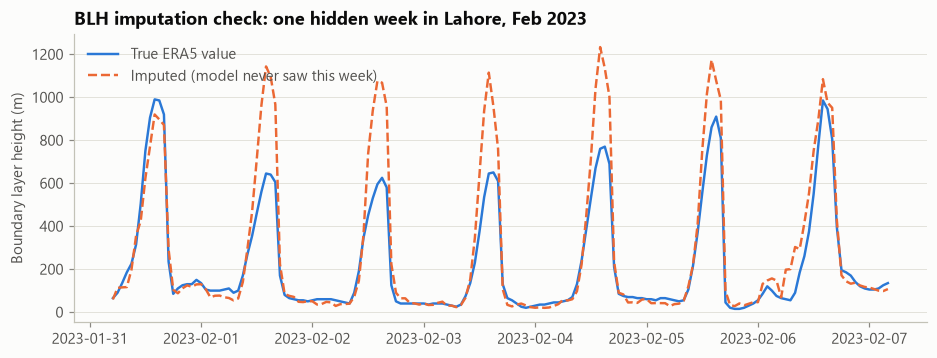

In [17]:
wx["hour_pkt"] = wx.time_pkt.dt.hour
wx["month"] = wx.time_utc.dt.month
wx["city_code"] = wx.city.astype("category").cat.codes
blh_x = ["temperature_2m", "relative_humidity_2m", "dew_point_2m", "precipitation", "surface_pressure", "cloud_cover",
         "wind_speed_10m", "wind_gusts_10m", "wind_speed_100m", "shortwave_radiation", "hour_pkt", "month", "city_code"]
known = wx.boundary_layer_height.notna()
mask23 = (wx.time_utc >= "2023-01-01") & (wx.time_utc < "2023-07-01")
blh_model = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=63, verbose=-1)
blh_model.fit(wx.loc[known & ~mask23, blh_x], np.log1p(wx.loc[known & ~mask23, "boundary_layer_height"]))
pred23 = np.expm1(blh_model.predict(wx.loc[mask23, blh_x]))
true23 = wx.loc[mask23, "boundary_layer_height"].to_numpy()
mae = np.abs(pred23 - true23).mean()
corr = np.corrcoef(pred23, true23)[0, 1]
print(f"Validation on hidden Jan-Jun 2023: MAE = {mae:.0f} m, correlation = {corr:.3f}, true median = {np.median(true23):.0f} m")

fig, ax = plt.subplots(figsize=(10, 3.4))
w = wx.loc[mask23 & (wx.city == "lahore")].iloc[24 * 30: 24 * 37]
ax.plot(w.time_pkt, w.boundary_layer_height, color=viz.SERIES[0], label="True ERA5 value")
ax.plot(w.time_pkt, np.expm1(blh_model.predict(w[blh_x])), color=viz.SERIES[1], ls="--", label="Imputed (model never saw this week)")
ax.set(title="BLH imputation check: one hidden week in Lahore, Feb 2023", ylabel="Boundary layer height (m)")
ax.legend(loc="upper left")
fig.savefig(FIG / "blh_imputation_check.png", bbox_inches="tight")
plt.show()

In [18]:
blh_model.fit(wx.loc[known, blh_x], np.log1p(wx.loc[known, "boundary_layer_height"]))
gap = ~known
wx["blh_imputed"] = gap
wx.loc[gap, "boundary_layer_height"] = np.expm1(blh_model.predict(wx.loc[gap, blh_x]))
log(8, "Weather", "missing boundary layer height (Jan-Jun 2024) imputed with LightGBM", len(wx), len(wx),
    f"{int(gap.sum()):,} values imputed; validation MAE {mae:.0f} m, r = {corr:.2f} on hidden Jan-Jun 2023")

[step 8] Weather: missing boundary layer height (Jan-Jun 2024) imputed with LightGBM: 266,760 -> 266,760 (0 removed). 21,840 values imputed; validation MAE 148 m, r = 0.91 on hidden Jan-Jun 2023


### Secondary pollutants: PM10 and NO2

The proposal planned PM2.5, PM10 and NO2. The coverage check found **no NO2 sensor at all** within 25 km of the five cities in OpenAQ, and only **5 PM10 sensors** (two Clarity monitors in Lahore and Karachi, three short-lived AirGradient units). PM10 goes through the same rules (nulls, negatives, a 2,000 ug/m3 ceiling since dust storms push PM10 far above PM2.5, stuck runs) and joins the master table as context. It is not a model feature: it exists for too few cities and hours.

In [19]:
p = pm10_raw.sort_values(["sensor_id", "time_utc"]).reset_index(drop=True)
n = len(p); p = p[p.value.notna() & (p.value >= 0) & (p.value <= 2000)]
log(3, "OpenAQ PM10", "null, negative and >2,000 ug/m3 readings dropped", n, len(p))
same10 = (p.value == p.groupby("sensor_id").value.shift()) & (p.time_utc - p.groupby("sensor_id").time_utc.shift() == pd.Timedelta("1h"))
run10 = p.groupby((~same10).cumsum()).value.transform("size")
n = len(p); p = p[run10 < 6]; log(4, "OpenAQ PM10", "stuck runs (same value 6+ hours) removed", n, len(p))
pm10_city = p.groupby(["city", "time_utc"]).value.median().rename("pm10").reset_index()
print("PM10 hours per city:", pm10_city.groupby("city").size().to_dict())

[step 3] OpenAQ PM10: null, negative and >2,000 ug/m3 readings dropped: 5,904 -> 5,903 (1 removed). 
[step 4] OpenAQ PM10: stuck runs (same value 6+ hours) removed: 5,903 -> 5,903 (0 removed). 
PM10 hours per city: {'karachi': 2426, 'lahore': 3477}


## Step 9 · Integration: the hourly master table

One row per city per hour, 1 Jan 2020 to 31 Jan 2026: weather (backbone), the city PM2.5 series with its source and flags, PM10 where it exists, hourly fire activity within 300 km of the city, and two event tags. The detailed, wind-weighted fire index is built from `fires_clean.parquet` in notebook 04.

In [20]:
fire_city = []
for c in CITIES.values():
    d = haversine_km(c.lat, c.lon, fires.latitude.to_numpy(), fires.longitude.to_numpy())
    near = fires[d <= 300]
    fire_city.append(near.groupby("hour_utc").agg(fires_300km=("frp", "size"), frp_300km=("frp", "sum"))
                     .reset_index().rename(columns={"hour_utc": "time_utc"}).assign(city=c.slug))
fire_city = pd.concat(fire_city)

master = (wx.drop(columns=["hour_pkt", "month", "city_code"])
          .merge(pm[["city", "time_utc", "pm25", "pm25_source", "pm25_interpolated", "gap_hours", "long_gap", "n_low"]],
                 on=["city", "time_utc"], how="left")
          .merge(pm10_city, on=["city", "time_utc"], how="left")
          .merge(fire_city, on=["city", "time_utc"], how="left"))
master[["fires_300km", "frp_300km"]] = master[["fires_300km", "frp_300km"]].fillna(0)
master["pm25_interpolated"] = master.pm25_interpolated.fillna(False).astype(bool)
master["is_test_season"] = in_test(master.time_utc)

# event tags (step 5): genuine extremes are kept and marked, never deleted
master["extreme_event"] = master.pm25 >= 250
local = master.time_pkt.dt.tz_localize(None)
master["fireworks_night"] = False
for d in pd.to_datetime(fireworks):
    master.loc[(local >= d + pd.Timedelta(hours=18)) & (local < d + pd.Timedelta(hours=33)), "fireworks_night"] = True
print("extreme-event hours per city:", master[master.extreme_event].groupby("city").size().to_dict())

master = master.sort_values(["city", "time_utc"]).reset_index(drop=True)
master.to_parquet(PROCESSED / "master_hourly.parquet", index=False)
fires.drop(columns=["cell"]).to_parquet(PROCESSED / "fires_clean.parquet", index=False)

# CSV copies a person can open: one file per city (Excel-friendly, Pakistan time first), and a small
# sample that GitHub displays as a table in the browser
CSV = PROCESSED / "csv"
CSV.mkdir(exist_ok=True)
export = master.assign(time_pkt=master.time_pkt.dt.strftime("%Y-%m-%d %H:%M"), time_utc=master.time_utc.dt.strftime("%Y-%m-%d %H:%M"))
cols = ["city", "time_pkt", "time_utc"] + [c for c in export.columns if c not in ("city", "time_pkt", "time_utc")]
for c, g in export[cols].groupby("city"):
    g.to_csv(CSV / f"master_hourly_{c}.csv", index=False, float_format="%.2f")
export[cols][(export.city == "lahore") & export.time_pkt.between("2024-11-01", "2024-11-08")].to_csv(
    PROCESSED / "sample_lahore_1-7_nov_2024.csv", index=False, float_format="%.2f")
log(9, "All sources", "merged into one hourly master table (city x hour)", len(master), len(master),
    f"{master.shape[1]} columns; {int(master.pm25.notna().sum()):,} city-hours with PM2.5")
print(master.shape)
master[master.pm25.notna()].sample(5, random_state=0)

extreme-event hours per city: {'faisalabad': 1147, 'islamabad': 401, 'karachi': 219, 'lahore': 5564, 'multan': 889}


[step 9] All sources: merged into one hourly master table (city x hour): 266,760 -> 266,760 (0 removed). 29 columns; 137,596 city-hours with PM2.5
(266760, 29)


,city,time_utc,temperature_2m,relative_humidity_2m,dew_point_2m,precipitation,surface_pressure,cloud_cover,wind_speed_10m,wind_direction_10m,...,pm25_interpolated,gap_hours,long_gap,n_low,pm10,fires_300km,frp_300km,is_test_season,extreme_event,fireworks_night
61260,islamabad,2020-11-25 12:00:00+00:00,12.1,88,10.3,0.8,957.2,100,1.39,339,...,False,0,False,NaN,NaN,0.0,0.0,False,False,False
112294,karachi,2020-08-20 22:00:00+00:00,28.4,92,27.1,0.0,998.8,90,2.01,297,...,False,0,False,NaN,NaN,0.0,0.0,False,False,False
77554,islamabad,2022-10-05 10:00:00+00:00,32.2,27,10.6,0.0,948.9,0,2.50,272,...,False,0,False,NaN,NaN,0.0,0.0,False,False,False
166355,lahore,2020-09-19 11:00:00+00:00,37.3,32,17.8,0.0,975.0,7,2.30,272,...,False,0,False,NaN,NaN,0.0,0.0,False,False,False
196390,lahore,2024-02-22 22:00:00+00:00,8.3,69,2.9,0.0,988.4,0,2.10,3,...,False,0,False,1.0,254.0,0.0,0.0,False,False,False


### What the cleaned data shows: smog seasons in the three long-record cities

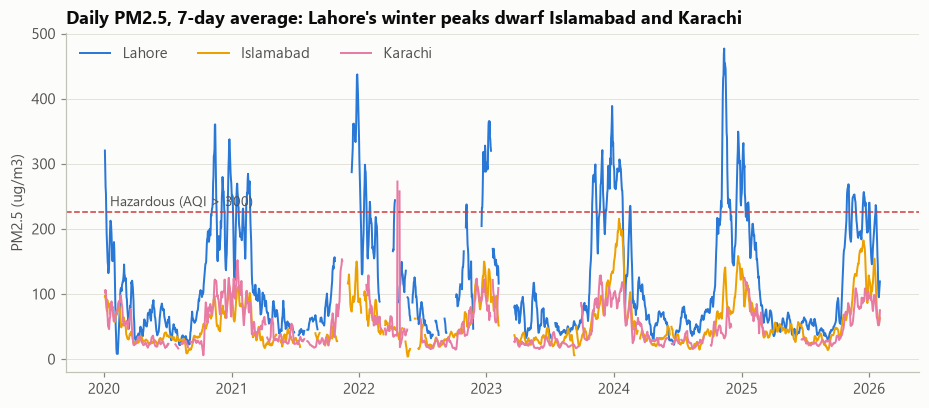

In [21]:
daily = (master.assign(day=master.time_pkt.dt.tz_localize(None).dt.floor("D"))
         .groupby(["city", "day"]).pm25.mean().reset_index())
fig, ax = plt.subplots(figsize=(10, 4))
for city in ["lahore", "islamabad", "karachi"]:
    s = daily[daily.city == city].set_index("day").pm25.rolling(7, min_periods=4).mean()
    ax.plot(s.index, s.values, color=viz.CITY_COLORS[city], label=CITIES[city].name, lw=1.3)
ax.axhline(225.5, color=viz.STATUS["critical"], lw=1, ls="--")
ax.annotate("Hazardous (AQI > 300)", (daily.day.min(), 225.5), xytext=(4, 4), textcoords="offset points", color=viz.INK_2, fontsize=9)
ax.set(title="Daily PM2.5, 7-day average: Lahore's winter peaks dwarf Islamabad and Karachi", ylabel="PM2.5 (ug/m3)")
ax.legend(loc="upper left", ncol=3)
fig.savefig(FIG / "pm25_daily_by_city.png", bbox_inches="tight")
plt.show()

## The Data Quality Report

Every `log()` call above, in order, plus before/after totals. Saved as `reports/data_quality_report.md`.

In [22]:
dq = pd.DataFrame(LOG)
aq_kept = int(len(aq))
totals = pd.DataFrame([
    ("Open-Meteo weather", RAW["weather"], len(wx), "all hours kept; 21,840 BLH values imputed"),
    ("OpenAQ PM2.5 sensor-hours", RAW["openaq"], aq_kept, "nulls, invalid values, faults, spikes and dropouts removed"),
    ("OpenAQ PM10 sensor-hours", RAW["openaq_pm10"], len(p), "nulls, invalid values and stuck runs removed"),
    ("NASA FIRMS detections", RAW["fires"], len(fires), "low confidence, static sources removed; repeat passes merged"),
    ("GDELT headlines", RAW["news"], len(news), "already de-duplicated at download"),
], columns=["source", "received", "after_cleaning", "summary"])
totals["share_kept"] = (totals.after_cleaning / totals.received).map("{:.1%}".format)

# sensors rejected: a sensor is kept if at least 24 valid hours survive cleaning
kept_per_sensor = aq.groupby("sensor_id").size().rename("hours_kept")
sens = raw_per_sensor.reset_index().merge(kept_per_sensor, on="sensor_id", how="left").fillna({"hours_kept": 0})
sens["kept"] = sens.hours_kept >= 24
sensor_table = (sens.groupby("provider").agg(sensors_received=("sensor_id", "size"), sensors_kept=("kept", "sum"),
                                             hours_received=("hours_received", "sum"), hours_kept=("hours_kept", "sum"))
                .astype(int).reset_index())
sensor_table["sensors_rejected"] = sensor_table.sensors_received - sensor_table.sensors_kept
print(sensor_table.to_string(index=False))

def md_table(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for r in df.itertuples(index=False):
        lines.append("| " + " | ".join(f"{v:,}" if isinstance(v, (int, np.integer)) else str(v) for v in r) + " |")
    return "\n".join(lines)

report = f"""# SAANS Data Quality Report

Generated by `notebooks/02_data_cleaning.ipynb`. Every number below is computed, not typed.

## Totals: received vs kept

{md_table(totals)}

Total raw records received: **{sum(RAW.values()):,}**.

## Every cleaning action, in order

{md_table(dq[["step", "source", "action", "rows_before", "rows_after", "removed", "note"]])}

## Sensors received, kept and rejected

A sensor is kept if at least 24 valid hours survive cleaning; otherwise it is rejected.

{md_table(sensor_table[["provider", "sensors_received", "sensors_kept", "sensors_rejected", "hours_received", "hours_kept"]])}

No sensor within 25 km of the five cities reports NO2 in OpenAQ, so NO2 (planned in the proposal) could not be collected.

## Humidity-correction check (step 6)

Each low-cost provider vs a reference monitor in the same city and hour (test seasons excluded):

{md_table(correction_check) if len(correction_check) else "No overlap of 200+ hours between low-cost and reference data."}

## PM2.5 series per city (step 8)

{md_table(pm.groupby("city").agg(hours_with_pm25=("pm25", lambda s: int(s.notna().sum())), share_of_hours=("pm25", lambda s: f"{s.notna().mean():.0%}"), interpolated=("pm25_interpolated", lambda s: int(s.sum())), hours_in_long_gaps=("long_gap", lambda s: int(s.sum()))).reset_index())}

## Where the cleaned data is

* `data/processed/master_hourly.parquet`: the full hourly master table (all cities)
* `data/processed/csv/master_hourly_<city>.csv`: the same table as one CSV per city (opens in Excel)
* `data/processed/sample_lahore_1-7_nov_2024.csv`: one week, small enough for GitHub to show as a table
* `data/processed/fires_clean.parquet`: cleaned fire detections; `data/processed/events.json`: the LLM event calendar
* Column meanings: `data/README.md`

## Known limitations

* Faisalabad and Multan have PM2.5 only from June 2025 (AirGradient low-cost network); there is no reference monitor in either city.
* The US diplomatic-post monitors (reference data for Lahore, Islamabad and Karachi) stopped publishing on 4 March 2025.
* ERA5 weather is a ~25 km grid estimate, not a street-level station; BLH for Jan-Jun 2024 is imputed.
* Fireworks-night dates for Shab-e-Barat are approximate (+-1 day).
"""
(REPORTS / "data_quality_report.md").write_text(report, encoding="utf-8")
dq

          provider  sensors_received  sensors_kept  hours_received  hours_kept  sensors_rejected
       AirGradient               103           100          353065      350469                 3
            AirNow                 2             2           70305       60040                 0
           Clarity                 2             2           17723       16125                 0
          Hawanama                91            84           67169       66224                 7
StateAir Islamabad                 1             1           38403       31787                 0
   StateAir Lahore                 1             1           41304       32321                 0


,step,source,action,rows_before,rows_after,removed,note
0,1,OpenAQ,timestamps checked and snapped to the UTC hour,587969,587969,0,0 off-hour stamps snapped
1,1,FIRMS,HHMM integer times parsed to UTC; hour bucket ...,1185836,1185836,0,
2,2,OpenAQ,units verified (all ug/m3); AQI to be computed...,587969,587969,0,
3,3,OpenAQ,duplicate sensor-hours dropped,587969,587969,0,
4,3,OpenAQ,empty (null) readings dropped,587969,562414,25555,reference monitors' missing-hour markers
5,3,OpenAQ,negative concentrations dropped,562414,562414,0,
6,3,OpenAQ,zero readings dropped (below 1 ug/m3),562414,561394,1020,below the instruments' detection floor; urban ...
7,3,OpenAQ,"values above 1,000 ug/m3 dropped",561394,561394,0,
8,3,OpenAQ,hours with <75% of the sensor's normal reading...,561394,559860,1534,judged per sensor; OpenAQ's percentComplete as...
9,3,FIRMS,exact duplicate detections dropped,1185836,1185836,0,
